# 🧠 Memahami Linear Regression dari Nol
### Pertanyaan Utama: **"Apa itu $w$ dan $b$, serta dapetnya dari mana?"**

Selamat datang di notebook panduan ini! Notebook ini dirancang khusus untuk membedah konsep matematika dan logika di balik **Linear Regression** secara bertahap menggunakan data buatan sendiri.

---

### 📌 1. Apa itu $w$ dan $b$?
Di bangku sekolah, kita mengenal persamaan garis lurus:
$$y = mx + c$$

Di Machine Learning, rumusnya persis sama, hanya simbolnya disesuaikan:
$$f_{w,b}(x) = w \cdot x + b$$

Keterangan:
- **$x$ (Fitur / Input)**: Data masukan (contoh: Jam Belajar).
- **$f_{w,b}(x)$ (Prediksi)**: Hasil tebakan model (contoh: Perkiraan Nilai Ujian).
- **$w$ (Weight / Bobot / Kemiringan / Slope)**:
  - Menentukan **seberapa curam** garisnya.
  - Menggambarkan seberapa besar pengaruh input $x$ terhadap hasil prediksi.
  - *Artinya: Setiap $x$ bertambah 1 satuan, nilai $y$ akan bertambah sebesar $w$.*
- **$b$ (Bias / Intercept / Titik Potong Sumbu Y)**:
  - Menentukan **titik awal** garis saat $x = 0$.
  - *Artinya: Jika $x = 0$ (tidak belajar sama sekali), nilai dasarnya adalah $b$.*

---

### ❓ 2. Lalu $w$ dan $b$ dapet dari mana?
Nilai $w$ dan $b$ **tidak kita tebak secara manual**, melainkan **ditemukan oleh komputer secara otomatis** melalui proses yang disebut **Training**:
1. **Tebak Awal**: Komputer mulai dari nilai acak/sembarang (misal $w = 0, b = 0$).
2. **Ukur Kesalahan (Cost Function)**: Komputer menghitung seberapa jauh tebakannya meleset dari data asli.
3. **Perbaiki Nilai (Gradient Descent)**: Komputer menggeser nilai $w$ dan $b$ sedikit demi sedikit ke arah yang membuat kesalahan semakin mengecil.
4. **Garis Terbaik (Best Fit)**: Proses diulang sampai nilai kesalahan mencapai titik minimum.

In [23]:
# Import library pendukung untuk komputasi dan visualisasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Konfigurasi tampilan grafik agar rapi
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

print("✅ Library berhasil diimpor!")

✅ Library berhasil diimpor!


## 📊 Langkah 1: Membuat Dataset Sendiri (Synthetic Data)

Mari kita buat studi kasus sederhana:
- **$x$ = Jam Belajar per Hari** (1 sampai 10 jam)
- **$y$ = Nilai Ujian** (skala 0 - 100)

Kira-kira logika aslinya:
- Nilai dasar tanpa belajar ($b$) sekitar **30**.
- Tiap tambahan 1 jam belajar ($w$), nilai naik sekitar **6** poin.
- Tentu saja ada variasi/faktor keberuntungan acak (*noise*).

In [24]:
# Mengunci angka acak agar hasil selalu konsisten saat dijalankan ulang
np.random.seed(42)

# Buat 15 data jam belajar (antara 1 sampai 10 jam)
X = np.array([1.0, 1.5, 2.0, 2.8, 3.5, 4.0, 4.5, 5.2, 5.8, 6.5, 7.0, 7.8, 8.5, 9.0, 10.0])

# Pola buatan: y = 6 * x + 30 + sedikit acak (noise)
noise = np.random.normal(0, 3, size=len(X))
y = 6.2 * X + 32 + noise

# Tampilkan data dalam tabel
df = pd.DataFrame({
    'Jam_Belajar (x)': X,
    'Nilai_Ujian (y)': np.round(y, 1)
})

print("Total data:", len(X))
display(df.head(8))

Total data: 15


,Jam_Belajar (x),Nilai_Ujian (y)
0,1.0,39.7
1,1.5,40.9
2,2.0,46.3
3,2.8,53.9
4,3.5,53.0
5,4.0,56.1
6,4.5,64.6
7,5.2,66.5


### Visualisasi Data Awal
Mari kita lihat sebaran titik data asli ini dalam grafik (*Scatter Plot*).

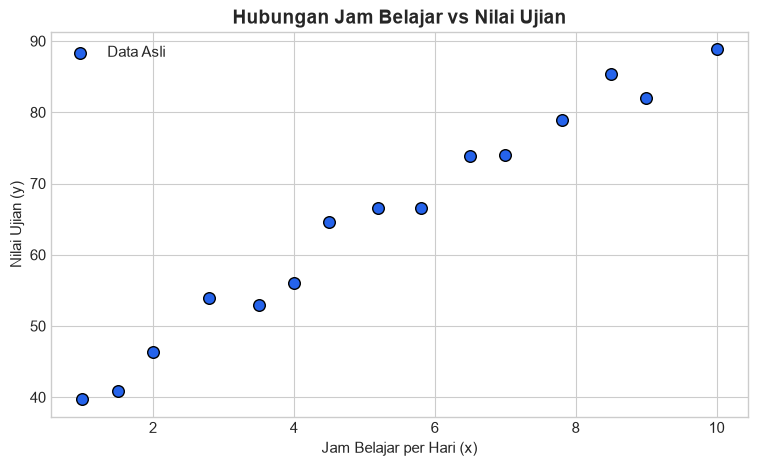

In [25]:
plt.scatter(X, y, color='#2563eb', s=70, edgecolor='black', label='Data Asli')
plt.title('Hubungan Jam Belajar vs Nilai Ujian', fontsize=14, fontweight='bold')
plt.xlabel('Jam Belajar per Hari (x)')
plt.ylabel('Nilai Ujian (y)')
plt.legend()
plt.show()

---
## 📐 Langkah 2: Fungsi Prediksi $f_{w,b}(x)$

Model kita menggunakan rumus:
$$f_{w,b}(x^{(i)}) = w \cdot x^{(i)} + b$$

Bagaimana kalau di awal kita **asal tebak** sembarang nilai, misalnya:
- $w = 2$
- $b = 10$

Mari kita lihat apakah tebakan sembarang ini cocok dengan data asli.

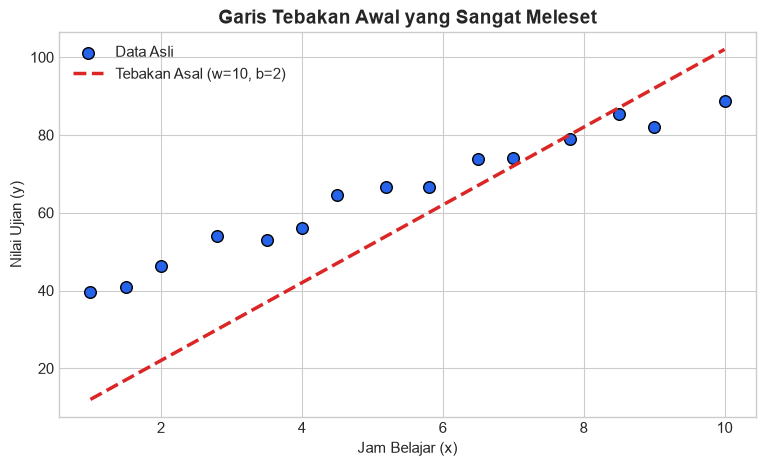

In [26]:
def predict(X, w, b):
    """
    nghitung prediksi garis linear: f(x) = w * x + b
    """
    return w * X + b

# Tebakan sembarang awal
w_tebakan = 10
b_tebakan = 2

y_prediksi_asal = predict(X, w_tebakan, b_tebakan)

# Visualisasi tebakan asal vs data asli
plt.scatter(X, y, color='#2563eb', s=70, edgecolor='black', label='Data Asli')
plt.plot(X, y_prediksi_asal, color='#dc2626', linewidth=2.5, linestyle='--', label=f'Tebakan Asal (w={w_tebakan}, b={b_tebakan})')
plt.title('Garis Tebakan Awal yang Sangat Meleset', fontsize=14, fontweight='bold')
plt.xlabel('Jam Belajar (x)')
plt.ylabel('Nilai Ujian (y)')
plt.legend()
plt.show()

Terlihat jelas garis merah **terlalu jauh di bawah titik data**. 
Lalu bagaimana komputer tahu **seberapa parah** kesalahannya?

---
## 📉 Langkah 3: Mengukur Kesalahan dengan Cost Function $J(w, b)$

Ini adalah rumus yang ada di materi kuliah/slide kamu:

$$J(w, b) = \frac{1}{2m} \sum_{i=0}^{m-1} \left( f_{w,b}(x^{(i)}) - y^{(i)} \right)^2$$

Penjelasan komponen rumus:
1. **$f_{w,b}(x^{(i)})$** : Nilai yang ditebak oleh model untuk data ke-$i$.
2. **$y^{(i)}$** : Nilai nyata/aktual data ke-$i$.
3. **$\left( f_{w,b}(x^{(i)}) - y^{(i)} \right)$** : Selisih (error / melesetnya berapa).
4. **$(\dots)^2$** : Dikuadratkan agar selisih negatif tidak saling menghapus dan error besar diberi 'hukuman' lebih berat.
5. **$\sum_{i=0}^{m-1}$** : Jumlahkan semua kuadrat error untuk seluruh $m$ data.
6. **$\frac{1}{2m}$** : Dibagi jumlah data $m$ (mencari rata-rata error), dan angka $2$ di bawah adalah konstanta matematika agar saat diturunkan (derivatif) pangkat 2-nya tercoret rapi.

In [31]:
def compute_cost(X, y, w, b):
    """
    Menghitung nilai Cost Function J(w, b)
    """
    m = len(X)                       # Jumlah data
    predictions = predict(X, w, b)   # f(x) = w * x + b
    errors = predictions - y         # Selisih tebakan vs asli
    cost = (1 / (2 * m)) * np.sum(errors ** 2)
    print(predictions,cost)
    print(errors)
    return cost

cost_asal = compute_cost(X, y, w_tebakan, b_tebakan)
print(f"Nilai Error (Cost) untuk tebakan asal w={w_tebakan}, b={b_tebakan}: {cost_asal:.2f}")
print("Tujuan kita sekarang: Menurunkan nilai error ini hingga sekecil-kecilnya!")


[ 12.  17.  22.  30.  37.  42.  47.  54.  60.  67.  72.  80.  87.  92.
 102.] 126.54584718047698
[-27.69014246 -23.8852071  -24.34306561 -23.92908957 -15.99753988
 -14.09758913 -17.63763845 -12.54230419  -6.55157684  -6.92768013
  -2.00974692   1.03718926   1.57411319   9.93984073  13.1747535 ]
Nilai Error (Cost) untuk tebakan asal w=10, b=2: 126.55
Tujuan kita sekarang: Menurunkan nilai error ini hingga sekecil-kecilnya!


---
## 🚀 Langkah 4: Bagaimana Komputer Memperbaiki $w$ dan $b$? (Gradient Descent)

Komputer tidak boleh menebak secara buta. Komputer menghitung **kemiringan lereng (turunan parsial / gradient)** dari fungsi cost terhadap $w$ dan $b$.

Turunan parsial memberi tahu arah perubahan:
- Turunan terhadap $w$:
  $$\frac{\partial J}{\partial w} = \frac{1}{m} \sum_{i=0}^{m-1} \left( f_{w,b}(x^{(i)}) - y^{(i)} \right) x^{(i)}$$
- Turunan terhadap $b$:
  $$\frac{\partial J}{\partial b} = \frac{1}{m} \sum_{i=0}^{m-1} \left( f_{w,b}(x^{(i)}) - y^{(i)} \right)$$

Kemudian nilai $w$ dan $b$ **diperbarui bersamaan** dengan rumus:
$$w = w - \alpha \cdot \frac{\partial J}{\partial w}$$
$$b = b - \alpha \cdot \frac{\partial J}{\partial b}$$

Di mana **$\alpha$ (Alpha / Learning Rate)** adalah ukuran langkah (seberapa hati-hati komputer menggeser nilai $w$ dan $b$ di setiap langkah).

In [30]:
def compute_gradient(X, y, w, b):
    """
    Menghitung gradien (turunan parsial) dJ/dw dan dJ/db
    """
    m = len(X)
    predictions = predict(X, w, b)
    errors = predictions - y
    print (m)
    
    # Rumus turunan
    dj_dw = (1 / m) * np.sum(errors * X)
    dj_db = (1 / m) * np.sum(errors)
    
    return dj_dw, dj_db

dj_dw, dj_db = compute_gradient(X, y, w_tebakan, b_tebakan)
print(f"Gradien untuk w: {dj_dw:.2f} (arah perbaikan w)")
print(f"Gradien untuk b: {dj_db:.2f} (arah perbaikan b)")

15
Gradien untuk w: -19.37 (arah perbaikan w)
Gradien untuk b: -9.99 (arah perbaikan b)


---
## 🔄 Langkah 5: Proses Training (Komputer Belajar)

Sekarang kita biarkan komputer mengulang proses ini berkali-kali (*looping*) sampai nilai $w$ dan $b$ optimal ditemukan.

In [ ]:
# Inisialisasi awal
w = 0.0
b = 0.0

# Hyperparameters
learning_rate = 0.01
iterations = 10000

# Catat riwayat perubahan untuk diplot nanti
cost_history = []
w_history = []
b_history = []

for i in range(iterations):
    # 1. Hitung gradien arah perbaikan
    dj_dw, dj_db = compute_gradient(X, y, w, b)
    
    # 2. Update nilai w dan b (geser ke arah yang benar)
    w = w - learning_rate * dj_dw
    b = b - learning_rate * dj_db
    
    # 3. Hitung cost pada iterasi ini
    cost = compute_cost(X, y, w, b)
    cost_history.append(cost)
    w_history.append(w)
    b_history.append(b)
    
    # Tampilkan progress setiap 2000 iterasi
    if i % 2000 == 0 or i == iterations - 1:
        print(f"Iterasi {i:5d}: Cost = {cost:8.4f} | w = {w:.4f} | b = {b:.4f}")

print("\n🎉 Training Selesai!")
print(f"Nilai w akhir yang ditemukan : {w:.4f}")
print(f"Nilai b akhir yang ditemukan : {b:.4f}")

Iterasi     0: Cost = 976.5963 | w = 3.8299 | b = 0.6473
Iterasi  2000: Cost =   2.6299 | w = 5.6361 | b = 34.8949
Iterasi  4000: Cost =   2.6004 | w = 5.5582 | b = 35.4140
Iterasi  6000: Cost =   2.6004 | w = 5.5569 | b = 35.4221
Iterasi  8000: Cost =   2.6004 | w = 5.5569 | b = 35.4222
Iterasi  9999: Cost =   2.6004 | w = 5.5569 | b = 35.4222

🎉 Training Selesai!
Nilai w akhir yang ditemukan : 5.5569
Nilai b akhir yang ditemukan : 35.4222


Perhatikan output di atas!
- Nilai **Cost** yang awalnya sangat besar turun drastis mendekati titik minimum.
- Komputer berhasil menemukan:
  - **$w \approx 6.2$** (sesuai rumus pembuat data kita tadi!)
  - **$b \approx 32.2$**

Mari kita buat grafik penurunan error (Cost History) selama proses belajar:

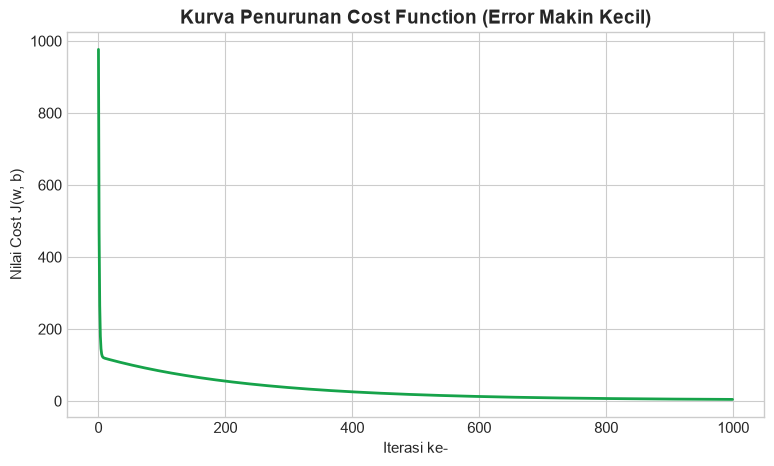

In [ ]:
plt.plot(range(1000), cost_history[:1000], color='#16a34a', linewidth=2)
plt.title('Kurva Penurunan Cost Function (Error Makin Kecil)', fontsize=14, fontweight='bold')
plt.xlabel('Iterasi ke-')
plt.ylabel('Nilai Cost J(w, b)')
plt.show()

---
## 📈 Langkah 6: Visualisasi Garis Terbaik (Best-Fit Line)

Sekarang kita gambar garis prediksi dengan nilai $w$ dan $b$ optimal yang didapat dari hasil training tadi.

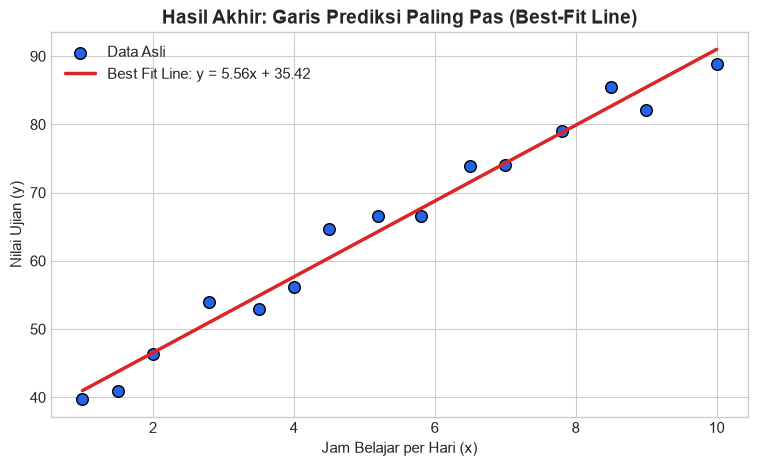

In [ ]:
# Garis prediksi optimal
y_final = predict(X, w, b)

plt.scatter(X, y, color='#2563eb', s=70, edgecolor='black', label='Data Asli')
plt.plot(X, y_final, color='#dc2626', linewidth=2.5, label=f'Best Fit Line: y = {w:.2f}x + {b:.2f}')
plt.title('Hasil Akhir: Garis Prediksi Paling Pas (Best-Fit Line)', fontsize=14, fontweight='bold')
plt.xlabel('Jam Belajar per Hari (x)')
plt.ylabel('Nilai Ujian (y)')
plt.legend()
plt.show()

### 🔮 Mencoba Prediksi Data Baru
Misal ada siswa baru yang belajar **6 jam per hari**, kira-kira berapa nilai ujiannya?

In [ ]:
jam_baru = 6.0
nilai_prediksi = predict(jam_baru, w, b)

print(f"Jika siswa belajar selama {jam_baru} jam per hari:")
print(f"Prediksi Nilai Ujian = ({w:.2f} * {jam_baru}) + {b:.2f} = {nilai_prediksi:.2f}")

Jika siswa belajar selama 6.0 jam per hari:
Prediksi Nilai Ujian = (5.56 * 6.0) + 35.42 = 68.76


---
## 🧪 Langkah 7: Bandingkan dengan Scikit-Learn (`LinearRegression`)

Di dunia kerja nyata, kamu tidak perlu mengetik rumus turunan Gradient Descent secara manual setiap saat.
Python memiliki library `scikit-learn` yang sudah otomatis menghitung ini.

Mari kita buktikan apakah rumus yang kita buat manual di atas menghasilkan angka yang sama dengan `scikit-learn`!

In [ ]:
from sklearn.linear_model import LinearRegression

# Scikit-Learn membutuhkan bentuk matriks 2D untuk fitur X
X_matrix = X.reshape(-1, 1)

# Inisialisasi dan training model
model_sklearn = LinearRegression()
model_sklearn.fit(X_matrix, y)

# Ambil nilai w dan b dari scikit-learn
w_sklearn = model_sklearn.coef_[0]
b_sklearn = model_sklearn.intercept_

print("=== PERBANDINGAN HASIL ===")
print(f"Perhitungan Manual Gradient Descent : w = {w:.4f}, b = {b:.4f}")
print(f"Library Scikit-Learn                 : w = {w_sklearn:.4f}, b = {b_sklearn:.4f}")
print("\nKeduanya menghasilkan nilai yang sama persis!")

=== PERBANDINGAN HASIL ===
Perhitungan Manual Gradient Descent : w = 5.5569, b = 35.4222
Library Scikit-Learn                 : w = 5.5569, b = 35.4222

Keduanya menghasilkan nilai yang sama persis!


---
## 📝 Kesimpulan Utama

1. **$w$ (Weight)**:
   - Mengontrol kemiringan garis.
   - Menjelaskan seberapa besar kenaikan $y$ untuk setiap 1 kenaikan pada $x$.
2. **$b$ (Bias)**:
   - Titik potong sumbu $y$ saat $x = 0$.
   - Menjelaskan nilai acuan dasar saat belum ada input $x$.
3. **Dapat dari mana?**:
   - Komputer memulai dengan angka tebakan ($w=0, b=0$).
   - Komputer mengukur tingkat kesalahan tebakan menggunakan rumus **Cost Function $J(w, b)$**.
   - Komputer mengoreksi nilai $w$ dan $b$ sedikit demi sedikit menggunakan **Gradient Descent** sampai nilai error berada di titik terendah.
   - Pasangan angka $w$ dan $b$ terbaik yang ditemukan itulah yang dipakai untuk memprediksi data masa depan!